# Diabetes ML v2: nested evaluation and prediabetes experiments

Development-only analysis. Original test results remain historical. See REPORT.md for the protocol and limits.

In [1]:
import json
import pandas as pd
from IPython.display import display, Image
from diabetes_ml.v2_protocol import OUT
display(json.loads((OUT/'summary.json').read_text()))
display(pd.read_csv(OUT/'oof_summary.csv'))

{'completed_at_utc': '2026-10-28T15:45:21.233563+00:00',
 'elapsed_seconds': 671.6445434093475,
 'outer_folds': 3,
 'inner_folds': 2,
 'candidate_configurations': 18,
 'candidate_decision_variants': 108,
 'historic_artifacts_unchanged': True,
 'historic_test_rows_used': 0,
 'development_rows': 228312,
 'final_model': {'name': 'catboost_0',
  'kind': 'catboost',
  'mode': 'raw_macro',
  'inner_fold': 0.5,
  'fit_seconds': 2.773775815963745,
  'accuracy': 0.8027874137145661,
  'balanced_accuracy': 0.4813743445177896,
  'macro_f1': 0.4668486881316626,
  'prediabetes_recall': 0.06693857965451055,
  'prediabetes_precision': 0.045363377929107176,
  'diabetes_recall': 0.510027662517289,
  'prediabetes_ap': 0.03736589833681113,
  'log_loss': 0.39387809695106357,
  'brier': 0.220690197646916,
  'decision_constraint_feasible': 1.0,
  'selection_constraint_feasible': True},
 'recall_model': {'name': 'mlp_focal_g1',
  'kind': 'mlp',
  'mode': 'raw_recall',
  'inner_fold': 0.5,
  'fit_seconds': 4.6

,method,accuracy,macro_f1,balanced_accuracy,prediabetes_recall,prediabetes_precision,diabetes_recall,prediabetes_ap
0,fixed_plain_mlp,0.848168,0.415790,0.402889,0.000000,0.000000,0.241827,0.034127
1,fixed_weighted_mlp,0.808994,0.462162,0.471705,0.042226,0.038244,0.495411,0.032024
2,selected_mlp,0.785543,0.464004,0.487615,0.103887,0.041082,0.513674,0.027750
3,selected_catboost,0.814578,0.465138,0.470629,0.049904,0.044416,0.474601,0.028597
4,prediabetes_focused,0.832825,0.430676,0.416252,0.039347,0.041299,0.265560,0.029189
5,selected_overall,0.801981,0.465947,0.479063,0.075336,0.043286,0.493022,0.028594


## Outer-fold variability
Dots show separate outer evaluations; error bars are fold standard deviations.

,method,fold,name,seed,mode,accuracy,balanced_accuracy,macro_f1,prediabetes_recall,prediabetes_precision,diabetes_recall,prediabetes_ap,log_loss,brier,offsets,decision_constraint_feasible
0,fixed_plain_mlp,0,fixed_plain_mlp,42,raw_argmax,0.847551,0.402083,0.414698,0.000000,0.000000,0.239815,0.034688,0.396738,0.222900,"[0.0, 0.0, 0.0]",True
1,fixed_weighted_mlp,0,fixed_weighted_mlp,42,raw_macro,0.811587,0.468171,0.460418,0.035997,0.042992,0.486326,0.033900,0.483421,0.266720,"[0.0, 0.75, 0.0]",True
2,selected_mlp,0,mlp_focal_g1,42,calibrated_macro,0.775373,0.484600,0.458723,0.128870,0.037385,0.488023,0.034003,0.396179,0.222398,"[0.0, 3.0, 1.0]",True
3,selected_catboost,0,catboost_3,42,raw_macro,0.808499,0.471436,0.462642,0.049676,0.039451,0.486420,0.034978,0.481627,0.264378,"[0.0, 1.0, 0.0]",True
4,prediabetes_focused,0,mlp_random_oversampling,42,raw_recall,0.836329,0.394040,0.405946,0.046796,0.040000,0.172011,0.032258,0.461589,0.246240,"[0.0, 0.25, 0.0]",True
5,selected_overall,0,catboost_3,42,raw_macro,0.808499,0.471436,0.462642,0.049676,0.039451,0.486420,0.034978,0.481627,0.264378,"[0.0, 1.0, 0.0]",True
6,fixed_plain_mlp,1,fixed_plain_mlp,42,raw_argmax,0.847853,0.404144,0.416983,0.000000,0.000000,0.246794,0.033499,0.396949,0.222494,"[0.0, 0.0, 0.0]",True
7,fixed_weighted_mlp,1,fixed_weighted_mlp,42,raw_macro,0.810181,0.473133,0.464042,0.045356,0.038159,0.495190,0.031450,0.480703,0.267468,"[0.0, 0.75, 0.0]",True
8,selected_mlp,1,mlp_focal_g1,42,raw_macro,0.802179,0.481317,0.464967,0.050396,0.044558,0.530083,0.032975,0.481552,0.264037,"[0.0, 1.5, 0.25]",True
9,selected_catboost,1,catboost_1,42,calibrated_macro,0.818367,0.468819,0.465279,0.043916,0.046073,0.469728,0.035185,0.393110,0.220448,"[0.0, 2.75, 0.75]",True


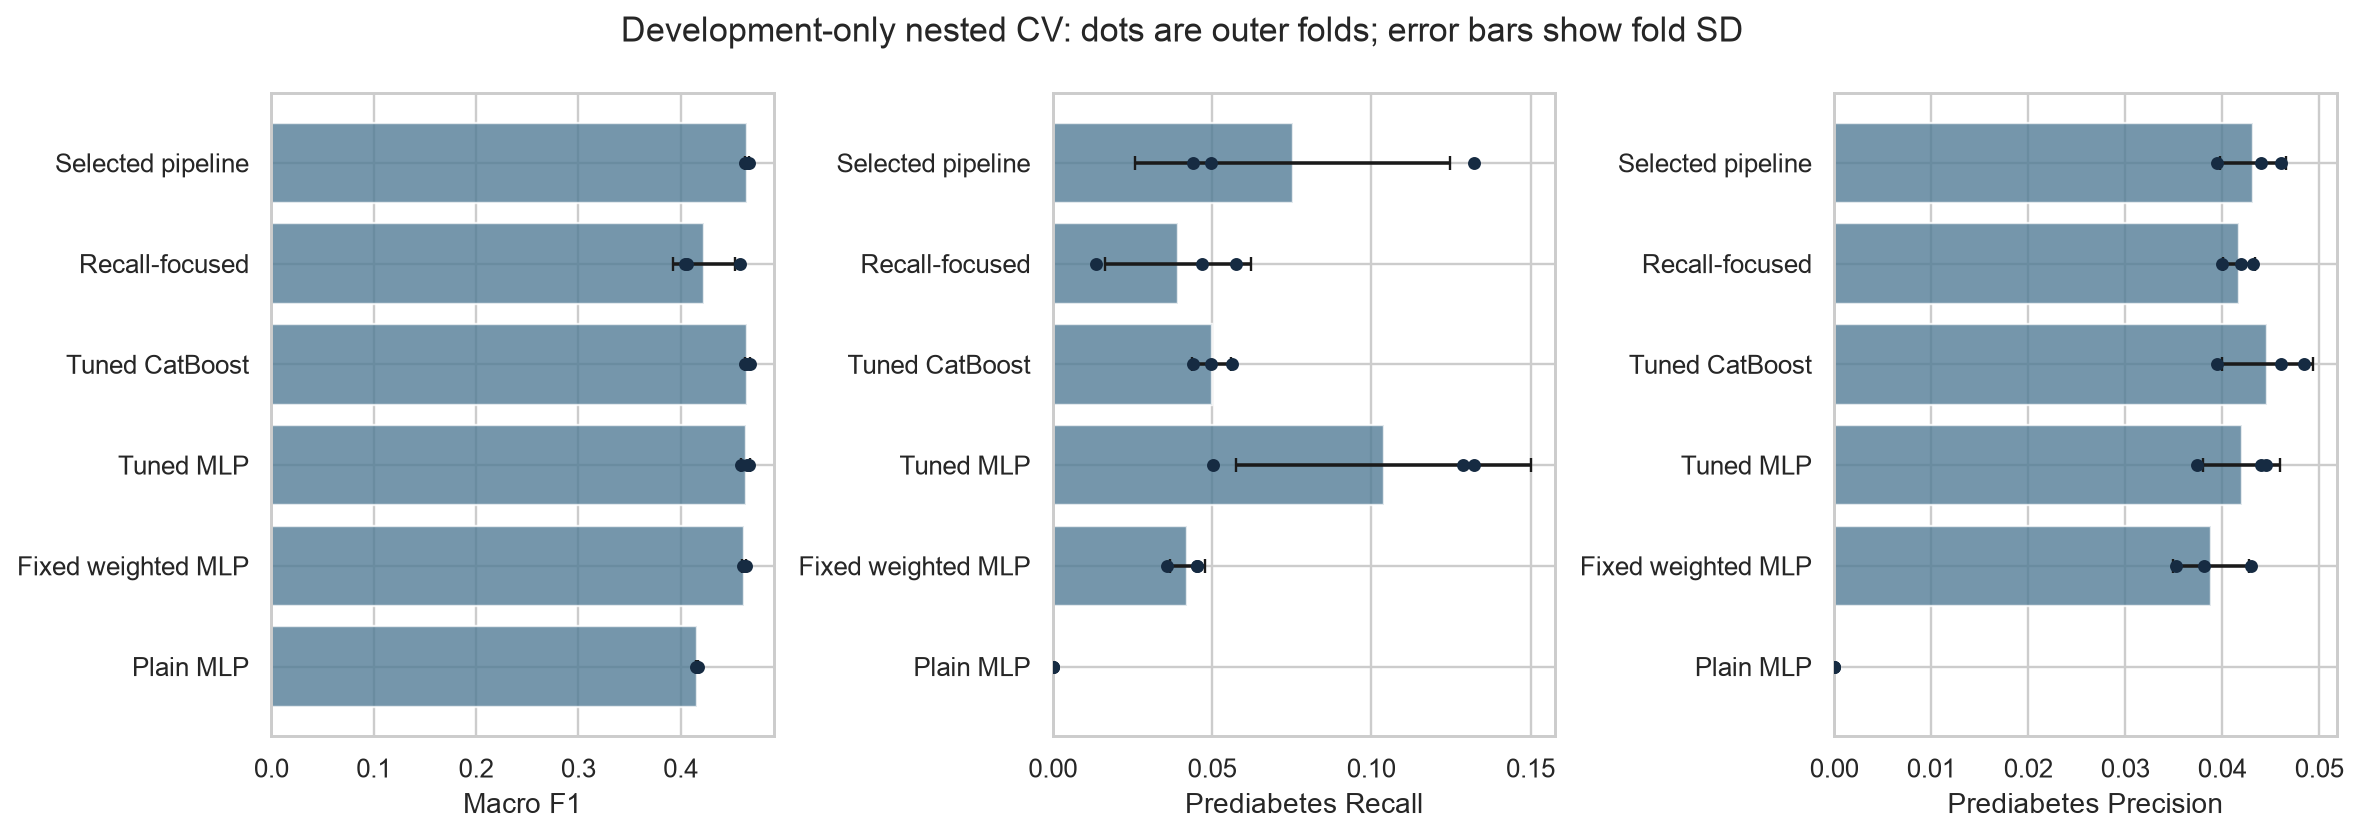

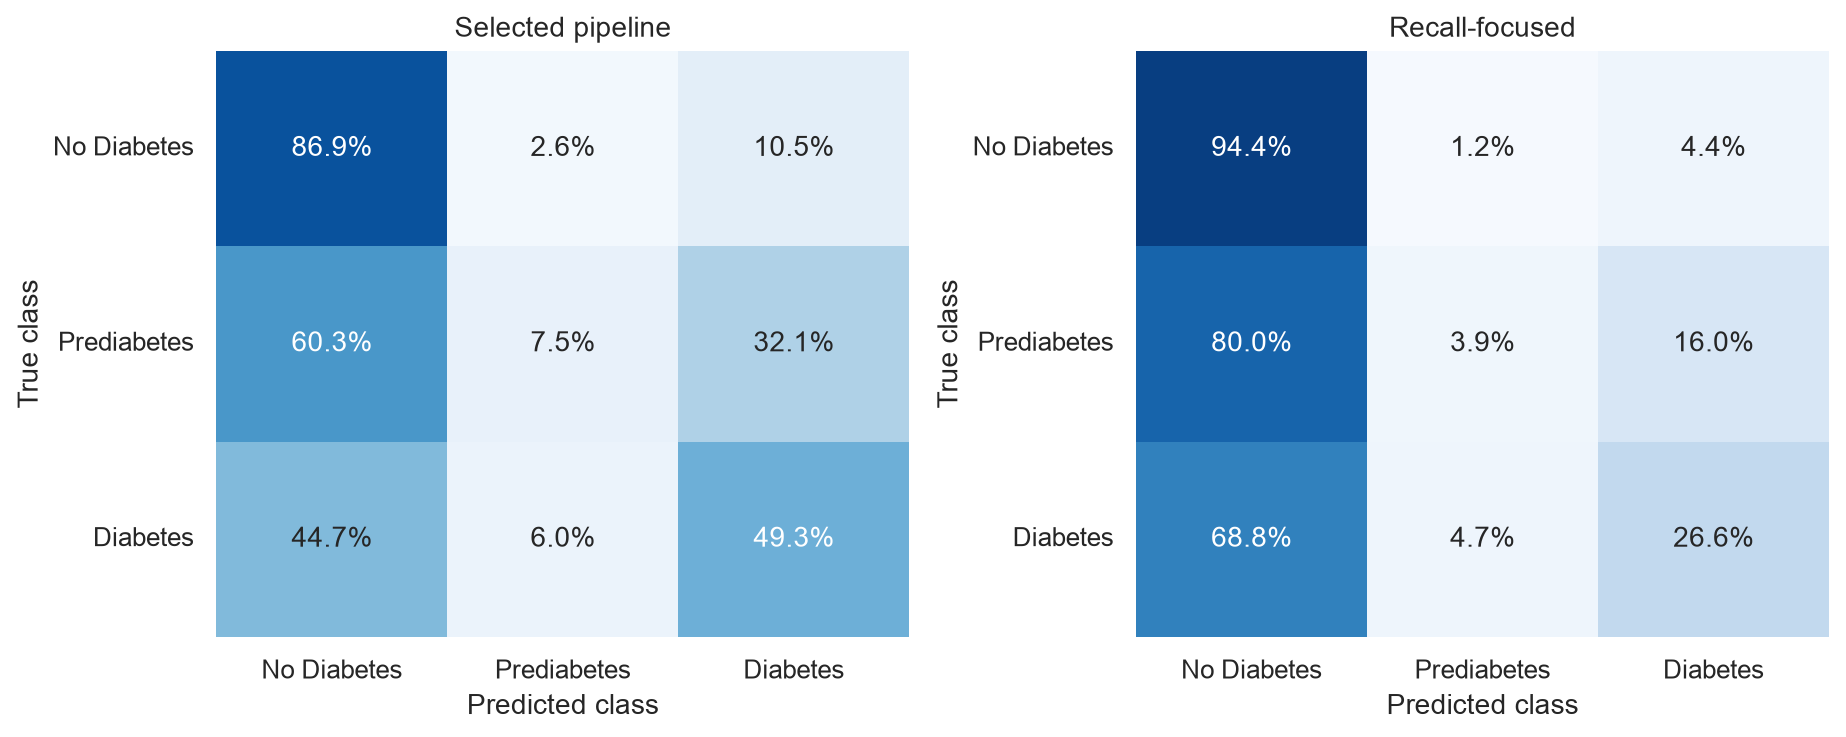

In [2]:
display(pd.read_csv(OUT/'outer_results.csv'))
display(Image(filename=str(OUT/'figures/nested_comparison.png')))
display(Image(filename=str(OUT/'figures/oof_confusion.png')))

## Prediabetes discrimination and calibration

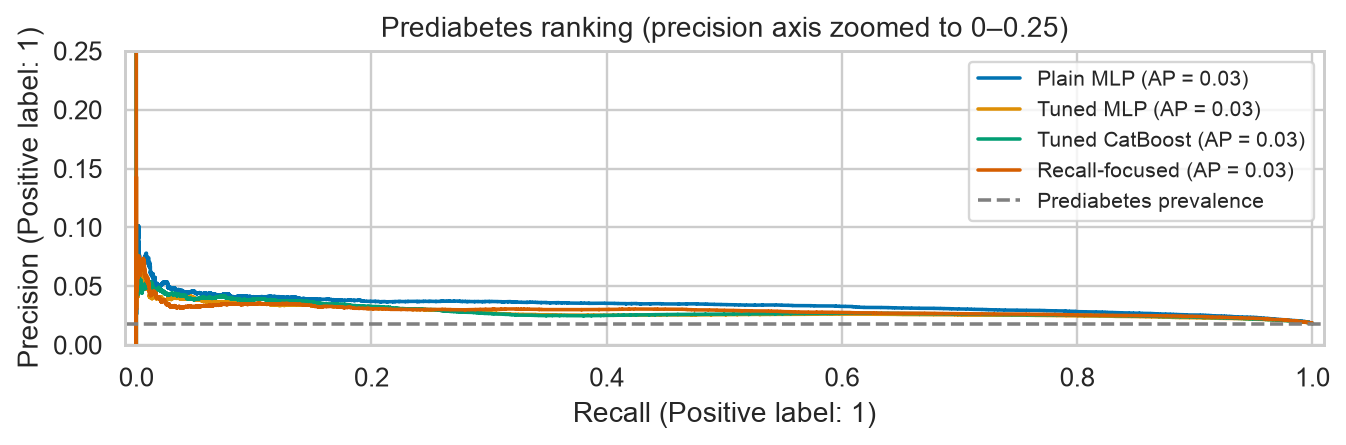

,fold,name,mode,accuracy,balanced_accuracy,macro_f1,prediabetes_recall,prediabetes_precision,diabetes_recall,prediabetes_ap,log_loss,brier,offsets,decision_constraint_feasible
0,0,fixed_plain_mlp,raw_argmax,0.847551,0.402083,0.414698,0.000000,0.000000,0.239815,0.034688,0.396738,0.222900,"[0.0, 0.0, 0.0]",True
1,0,fixed_plain_mlp,calibrated_argmax,0.848904,0.387035,0.397494,0.000000,0.000000,0.183799,0.035104,0.395767,0.222131,"[0.0, 0.0, 0.0]",True
2,0,fixed_weighted_mlp,raw_argmax,0.819050,0.463766,0.449562,0.000000,0.000000,0.502075,0.033900,0.483421,0.266720,"[0.0, 0.0, 0.0]",True
3,0,fixed_weighted_mlp,calibrated_argmax,0.848944,0.384558,0.394300,0.000000,0.000000,0.174840,0.035275,0.395686,0.222159,"[0.0, 0.0, 0.0]",True
4,0,mlp_focal_g1,raw_argmax,0.835186,0.439114,0.441866,0.000000,0.000000,0.390513,0.031568,0.481975,0.263901,"[0.0, 0.0, 0.0]",True
5,0,mlp_focal_g1,calibrated_argmax,0.848195,0.385285,0.395085,0.000000,0.000000,0.178518,0.034003,0.396179,0.222398,"[0.0, 0.0, 0.0]",True
6,0,catboost_3,raw_argmax,0.819352,0.467296,0.451697,0.000000,0.000000,0.514334,0.034978,0.481627,0.264378,"[0.0, 0.0, 0.0]",True
7,0,catboost_3,calibrated_argmax,0.848365,0.386218,0.396334,0.000000,0.000000,0.181630,0.035674,0.395145,0.221885,"[0.0, 0.0, 0.0]",True
8,0,mlp_random_oversampling,raw_argmax,0.843885,0.392006,0.406556,0.025198,0.054432,0.179272,0.032258,0.461589,0.246240,"[0.0, 0.0, 0.0]",True
9,0,mlp_random_oversampling,calibrated_argmax,0.848339,0.383348,0.392583,0.000000,0.000000,0.171350,0.032464,0.397223,0.222815,"[0.0, 0.0, 0.0]",True


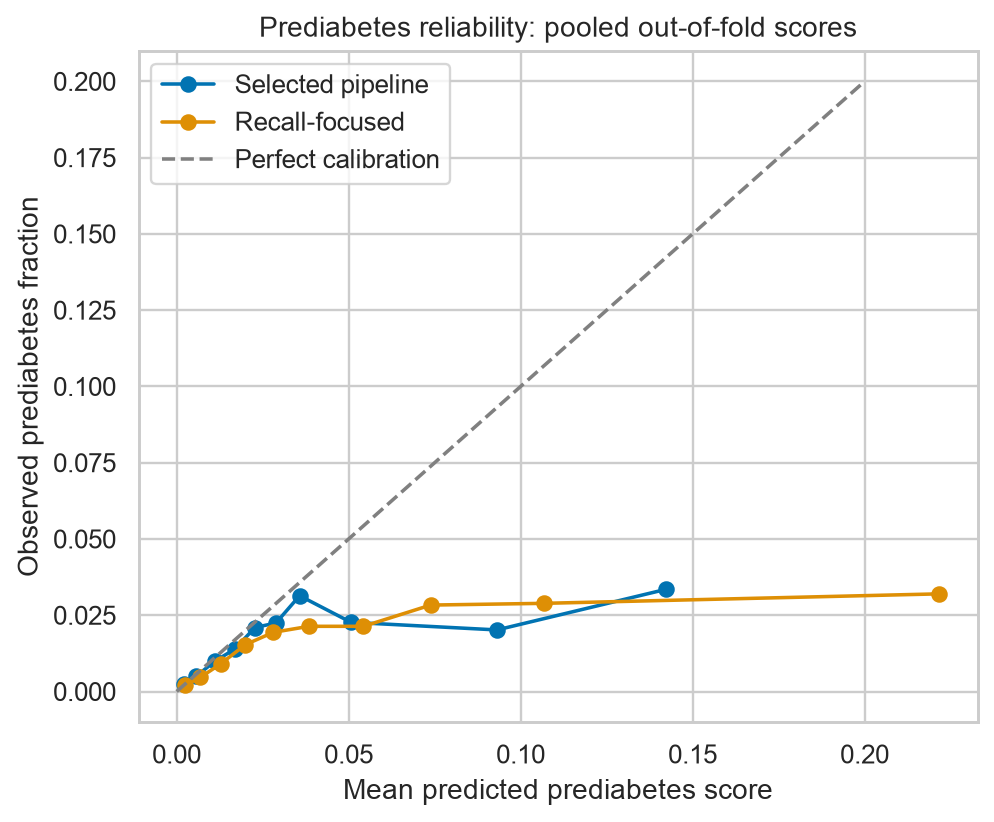

In [3]:
display(Image(filename=str(OUT/'figures/prediabetes_precision_recall.png')))
display(pd.read_csv(OUT/'calibration_results.csv'))
display(Image(filename=str(OUT/'figures/reliability.png')))

## Sampling, seeds, profile ambiguity and subgroups

In [4]:
display(pd.read_csv(OUT/'sampling_inner_summary.csv'))
display(pd.read_csv(OUT/'seed_results.csv'))
display(json.loads((OUT/'profile_audit.json').read_text()))
display(pd.read_csv(OUT/'grouped_sensitivity.csv'))
display(pd.read_csv(OUT/'subgroup_results.csv'))

,name,macro_f1,prediabetes_recall,prediabetes_precision,prediabetes_ap
0,fixed_plain_mlp,0.460793,0.061898,0.044726,0.034690
1,fixed_weighted_mlp,0.459051,0.097035,0.038608,0.032365
2,mlp_balanced_sampling,0.452132,0.079897,0.036313,0.027983
3,mlp_random_oversampling,0.457134,0.052906,0.041445,0.032686
4,mlp_smotenc,0.456822,0.030473,0.033765,0.029053


,fold,seed,name,mode,accuracy,balanced_accuracy,macro_f1,prediabetes_recall,prediabetes_precision,diabetes_recall,prediabetes_ap,log_loss,brier,offsets,decision_constraint_feasible
0,0,42,mlp_focal_g1,calibrated_macro,0.775373,0.484600,0.458723,0.128870,0.037385,0.488023,0.034003,0.396179,0.222398,"[0.0, 3.0, 1.0]",True
1,0,43,mlp_focal_g1,calibrated_macro,0.811784,0.465587,0.462302,0.070554,0.044749,0.436250,0.034917,0.395752,0.222371,"[0.0, 2.75, 0.75]",True
2,0,44,mlp_focal_g1,calibrated_macro,0.809773,0.465059,0.460707,0.067675,0.040395,0.440588,0.036499,0.395707,0.222349,"[0.0, 2.75, 0.75]",True
3,1,42,mlp_focal_g1,raw_macro,0.802179,0.481317,0.464967,0.050396,0.044558,0.530083,0.032975,0.481552,0.264037,"[0.0, 1.5, 0.25]",True
4,1,43,mlp_focal_g1,raw_macro,0.782600,0.483261,0.461677,0.101512,0.034593,0.504998,0.028877,0.488678,0.265666,"[0.0, 1.5, 0.25]",True
5,1,44,mlp_focal_g1,raw_macro,0.803611,0.474712,0.462908,0.055436,0.036667,0.498397,0.032339,0.475698,0.260335,"[0.0, 1.5, 0.25]",True
6,2,42,mlp_regularized_p075,calibrated_macro,0.779079,0.496920,0.466351,0.132374,0.044009,0.522916,0.036967,0.392874,0.220215,"[0.0, 3.0, 1.0]",True
7,2,43,mlp_regularized_p075,calibrated_macro,0.784124,0.487680,0.463310,0.098561,0.038332,0.522161,0.035823,0.393432,0.220488,"[0.0, 3.0, 1.0]",True
8,2,44,mlp_regularized_p075,calibrated_macro,0.802796,0.482207,0.461571,0.026619,0.043174,0.560260,0.036624,0.393147,0.220458,"[0.0, 2.75, 1.0]",True


{'development_rows': 228312,
 'unique_feature_profiles': 206269,
 'profiles_with_multiple_labels': 1554,
 'rows_in_conflicting_profiles': 5040,
 'prediabetes_rows_in_conflicting_profiles': 279,
 'interpretation': 'Identical coarse survey responses can occur for different people; conflicting labels do not by themselves establish annotation errors.'}

,fold,evaluation_rows,overlapping_profiles,mode,accuracy,balanced_accuracy,macro_f1,prediabetes_recall,prediabetes_precision,diabetes_recall,prediabetes_ap,log_loss,brier,offsets,decision_constraint_feasible
0,0,76105,0,raw_macro,0.808042,0.483281,0.471031,0.066187,0.057392,0.510279,0.034820,0.476096,0.264076,"[0.0, 0.75, 0.0]",True
1,1,76102,0,raw_macro,0.808862,0.465653,0.459975,0.053996,0.034404,0.460058,0.032612,0.479355,0.264823,"[0.0, 0.75, 0.0]",True
2,2,76105,0,raw_macro,0.808777,0.471273,0.460763,0.035277,0.040131,0.502310,0.030476,0.487869,0.271158,"[0.0, 0.75, 0.0]",True


,method,subgroup,rows,prediabetes_support,prediabetes_prevalence,prediabetes_precision,prediabetes_recall,macro_f1,prediabetes_ap
0,fixed_plain_mlp,sex_0,127788,2336,0.018280,0.000000,0.000000,0.419113,0.034390
1,fixed_plain_mlp,sex_1,100524,1832,0.018225,0.000000,0.000000,0.411761,0.034106
2,fixed_plain_mlp,age_1_to_5,48979,406,0.008289,0.000000,0.000000,0.370108,0.026082
3,fixed_plain_mlp,age_6_to_9,99231,1789,0.018029,0.000000,0.000000,0.422140,0.035548
4,fixed_plain_mlp,age_10_to_13,80102,1973,0.024631,0.000000,0.000000,0.402305,0.034469
5,fixed_plain_mlp,income_1_to_3,33915,977,0.028807,0.000000,0.000000,0.425969,0.041034
6,fixed_plain_mlp,income_4_to_6,74165,1619,0.021830,0.000000,0.000000,0.412099,0.035005
7,fixed_plain_mlp,income_7_to_8,120232,1572,0.013075,0.000000,0.000000,0.388370,0.027776
8,fixed_plain_mlp,conflicting_profile,5040,279,0.055357,0.000000,0.000000,0.268899,0.065843
9,fixed_plain_mlp,nonconflicting_profile,223272,3889,0.017418,0.000000,0.000000,0.420087,0.034049


## Saved development-model inference
These example predictions demonstrate artifact loading, not fresh validation.

In [5]:
from diabetes_ml.v2_predict import predict
inputs=pd.read_csv(OUT/'example_inputs.csv')
display(predict(inputs, policy='macro'))
display(predict(inputs, policy='recall'))

,predicted_class,predicted_label,score_class_0,score_class_1,score_class_2
0,2,Diabetes,0.338933,0.315948,0.345119
1,0,No Diabetes,0.372610,0.313222,0.314168
2,0,No Diabetes,0.350822,0.315573,0.333605
3,0,No Diabetes,0.367556,0.313882,0.318562
4,0,No Diabetes,0.362362,0.314704,0.322934


,predicted_class,predicted_label,score_class_0,score_class_1,score_class_2
0,2,Diabetes,0.363626,0.089505,0.546869
1,0,No Diabetes,0.826002,0.066688,0.107310
2,2,Diabetes,0.396440,0.107124,0.496435
3,0,No Diabetes,0.675038,0.082153,0.242809
4,0,No Diabetes,0.644163,0.098553,0.257284
